# Avance preliminar: DroneFace + ArcFace

Objetivo experimental: construir y documentar un baseline reproducible de reconocimiento facial closed-set sobre DroneFace usando InsightFace/ArcFace preentrenado. No se entrena una red desde cero, no se usa SCface y no se implementa control de dron.


## 2. Librerias y configuracion


In [ ]:
from pathlib import Path
import os
import re

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.config import (
    PROJECT_ROOT, DATA_DIR, DRONEFACE_ROOT, FIGS_DIR, OUTPUTS_DIR,
    INDEX_DIR, EMBEDDINGS_DIR, RESULTS_DIR, TABLES_DIR, CROPS_DIR, ensure_project_dirs,
)
from src.dataset_index import find_images, inspect_droneface_dataset, build_droneface_index
from src.face_model import FaceRecognizerArcFace
from src.evaluation import (
    build_gallery,
    evaluate_closed_set,
    detect_and_save_full_image_crops,
    build_crop_recognition_from_full_image_detections,
    evaluate_full_images,
    load_gallery_npz,
    compute_global_metrics,
    compute_grouped_metrics,
    compute_full_image_summary,
    compute_full_image_grouped_metrics,
    build_experiment_a_b_comparison,
    generate_preliminary_discussion,
)
from src.visualization import (
    plot_dataset_samples_droneface,
    plot_detection_examples,
    plot_recognition_examples,
    plot_metric_bar,
    plot_detection_vs_accuracy,
    plot_accuracy_heatmap_height_distance,
    plot_confusion_matrix,
    plot_full_image_detections,
    plot_experiment_a_vs_b,
    plot_full_image_recall_by_distance,
    plot_full_image_recall_heatmap_height_distance,
)
from src.synthetic_experiments import (
    DEFAULT_DEGRADATIONS,
    run_synthetic_degradation_experiment,
    plot_synthetic_degradation_summary,
    plot_synthetic_degradation_examples,
)

ensure_project_dirs()
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"DRONEFACE_ROOT: {DRONEFACE_ROOT}")


## 3. Exploracion de DroneFace


In [2]:
drone_info = inspect_droneface_dataset(DRONEFACE_ROOT, n_examples=30)
drone_paths = find_images(DRONEFACE_ROOT)
print(f"Total DroneFace images: {len(drone_paths)}")
if not drone_paths:
    raise RuntimeError("No DroneFace images found. Check data/DroneFace/open_data_set.")



=== DroneFace ===
Root: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\data\DroneFace\open_data_set
Exists: True
Images found: 2057
Images by main folder:
  photos_all: 620
  photos_all_faces: 1364
  portraits: 7
  trio_cam: 33
  trio_gp: 33
  other: 0
Extensions: ['.jpg']
First paths:
  C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\data\DroneFace\open_data_set\photos_all\ab_gp_0_eo_00.JPG
  C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\data\DroneFace\open_data_set\photos_all\ab_gp_0_eo_01.JPG
  C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\data\DroneFace\open_data_set\photos_all\ab_gp_0_eo_02.JPG
  C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\data\DroneFace\open_data_set\photos_all\ab_gp_0_eo_03.JPG
  C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\

## 4. Construccion del indice de DroneFace


In [3]:
drone_df = build_droneface_index(DRONEFACE_ROOT, save=True)
index_path = INDEX_DIR / "droneface_index.csv"
drone_df = pd.read_csv(index_path)

display(drone_df.head())
display(drone_df["source_folder"].value_counts(dropna=False).rename_axis("source_folder").reset_index(name="n"))
display(drone_df["image_type"].value_counts(dropna=False).rename_axis("image_type").reset_index(name="n"))
display(drone_df["subject_id"].value_counts(dropna=False).rename_axis("subject_id").reset_index(name="n"))
display(drone_df["split"].value_counts(dropna=False).rename_axis("split").reset_index(name="n"))
display(
    drone_df[drone_df["split"] == "probe"]
    .groupby(["height_m", "distance_m"], dropna=False)
    .size()
    .reset_index(name="n_probes")
    .sort_values(["height_m", "distance_m"])
)


Saved DroneFace index: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\indexes\droneface_index.csv


,path,filename,dataset,source_folder,subject_id,camera_type,height_id,height_m,image_type,distance_id,distance_m,is_single_subject,split,parsed,parse_error
0,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,ab_gp_0_eo_00.JPG,DroneFace,photos_all,ab,gp,0,1.5,eo,00,17.0,False,unused,True,NaN
1,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,ab_gp_0_eo_01.JPG,DroneFace,photos_all,ab,gp,0,1.5,eo,01,16.5,False,unused,True,NaN
2,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,ab_gp_0_eo_02.JPG,DroneFace,photos_all,ab,gp,0,1.5,eo,02,16.0,False,unused,True,NaN
3,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,ab_gp_0_eo_03.JPG,DroneFace,photos_all,ab,gp,0,1.5,eo,03,15.5,False,unused,True,NaN
4,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,ab_gp_0_eo_04.JPG,DroneFace,photos_all,ab,gp,0,1.5,eo,04,15.0,False,unused,True,NaN


,source_folder,n
0,photos_all_faces,1364
1,photos_all,620
2,trio_cam,33
3,trio_gp,33
4,portraits,7


,image_type,n
0,ef,1364
1,eo,620
2,porF,22
3,porL,22
4,porR,22
5,por,7


,subject_id,n
0,a,131
1,g,131
2,j,131
3,k,131
4,i,131
5,d,131
6,e,131
7,b,130
8,f,130
9,c,130


,split,n
0,probe,1364
1,unused,686
2,gallery,7


,height_m,distance_m,n_probes
0,1.5,2.0,11
1,1.5,2.5,11
2,1.5,3.0,11
3,1.5,3.5,11
4,1.5,4.0,11
...,...,...,...
119,5.0,15.0,11
120,5.0,15.5,11
121,5.0,16.0,11
122,5.0,16.5,11


## 5. Visualizacion inicial de ejemplos


Saved figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\dataset\droneface_samples.png
Figura generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\dataset\droneface_samples.png


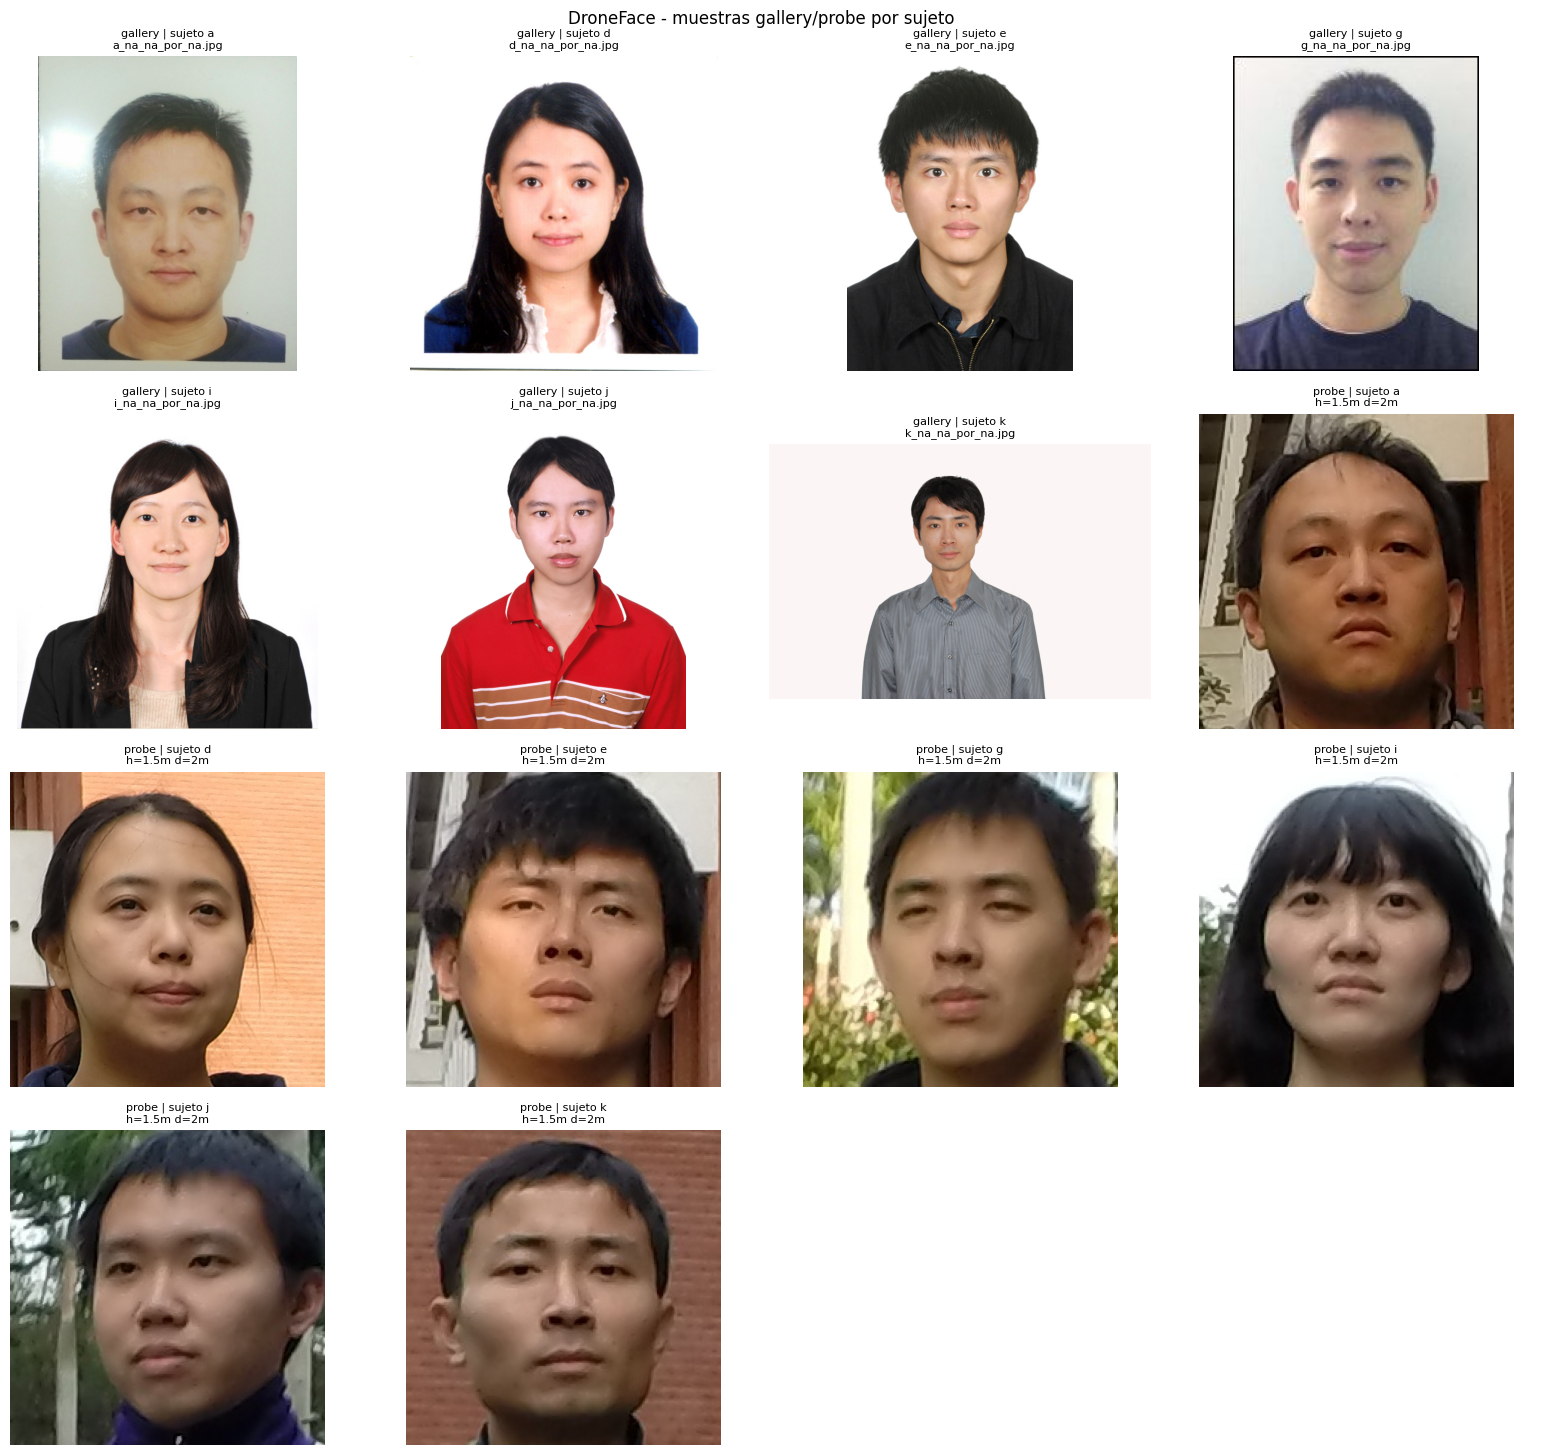

In [4]:
dataset_fig_path = FIGS_DIR / "dataset" / "droneface_samples.png"
plot_dataset_samples_droneface(drone_df, dataset_fig_path)
print(f"Figura generada: {dataset_fig_path}")


## 6. Inicializacion del modelo ArcFace


In [5]:
BASE_DET_SIZE = (320, 320)

try:
    model = FaceRecognizerArcFace(model_name="buffalo_l", det_size=BASE_DET_SIZE, allow_cuda=False)
except Exception as exc:
    print(f"ERROR initializing InsightFace/ArcFace: {type(exc).__name__}: {exc}")
    raise

print(f"Model: {model.model_name}")
print(f"Providers: {model.providers}")
print(f"Baseline det_size: {model.det_size}")


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\w600k_r50.onnx recognition ['None', 3, 112, 112] 127.

## 7. Ejemplos de deteccion facial


C:\Users\shipa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Saved detection examples: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\detection\droneface_detections.png
Figura generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\detection\droneface_detections.png


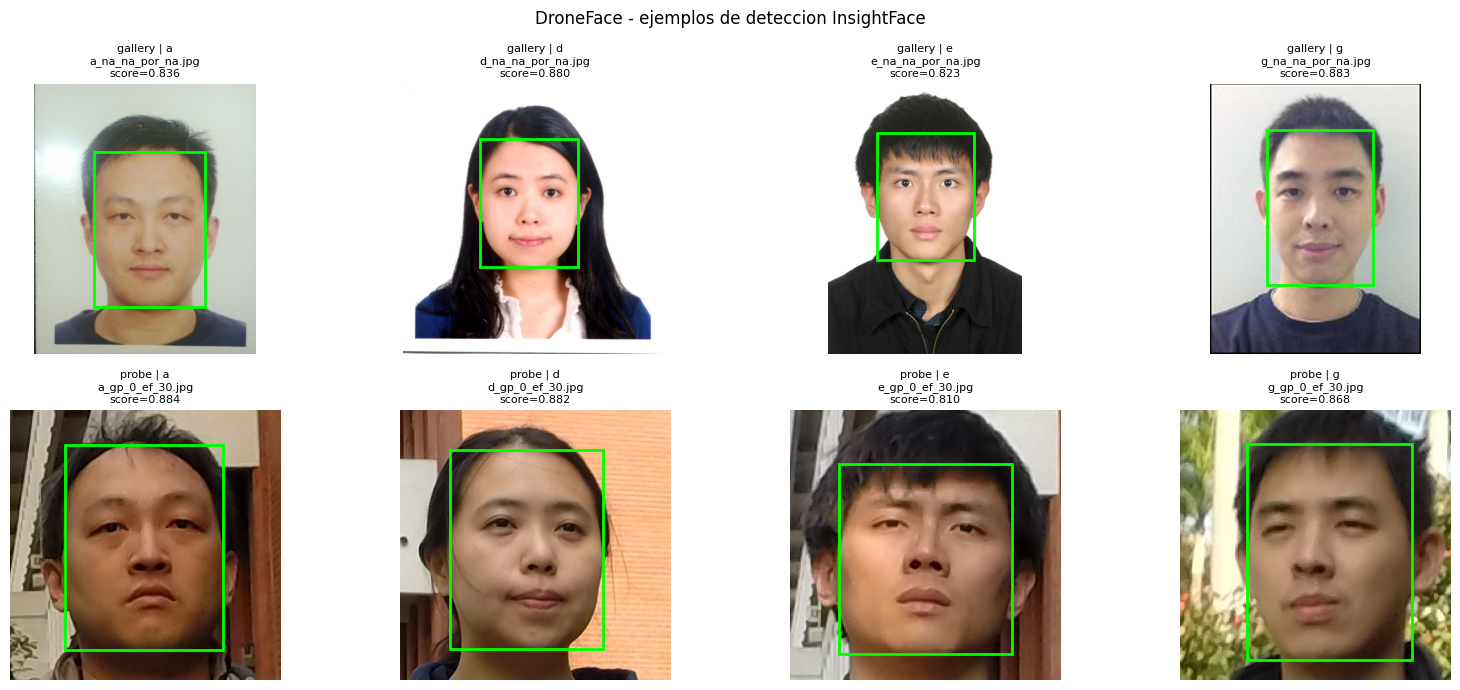

In [6]:
detections_fig_path = FIGS_DIR / "detection" / "droneface_detections.png"
plot_detection_examples(drone_df, model, detections_fig_path, max_images=8)
print(f"Figura generada: {detections_fig_path}")


## 8. Experimento A: galeria desde portraits


In [7]:
gallery_df = drone_df[drone_df["split"] == "gallery"].copy()
probe_df = drone_df[drone_df["split"] == "probe"].copy()
gallery_subjects_before = set(gallery_df["subject_id"].dropna().astype(str))
valid_probe_before = probe_df[probe_df["subject_id"].astype(str).isin(gallery_subjects_before)].copy()

print(f"Gallery rows: {len(gallery_df)}")
print(f"Probe rows: {len(probe_df)}")
print(f"Gallery subjects before detection: {len(gallery_subjects_before)}")
print(f"Probes excluded because subject has no gallery row: {len(probe_df) - len(valid_probe_before)}")
print(f"Probes eligible before detection: {len(valid_probe_before)}")

if gallery_df.empty:
    raise RuntimeError("No gallery rows found in droneface_index.csv.")
if probe_df.empty:
    raise RuntimeError("No probe rows found in droneface_index.csv.")
if valid_probe_before.empty:
    raise RuntimeError("No probes have subjects present in gallery.")

gallery_embeddings, gallery_info_df, gallery_failures_df = build_gallery(
    drone_df,
    model,
    dataset_name="DroneFace",
    save_path=EMBEDDINGS_DIR / "droneface_gallery_embeddings.npz",
    failures_path=TABLES_DIR / "gallery_failures_droneface.csv",
)

display(gallery_info_df)
print(f"Gallery subjects with valid embeddings: {len(gallery_embeddings)}")
if not gallery_embeddings:
    raise RuntimeError("No valid gallery embeddings were created.")


Gallery rows: 7
Probe rows: 1364
Gallery subjects before detection: 7
Probes excluded because subject has no gallery row: 496
Probes eligible before detection: 868


Building gallery:   0%|          | 0/7 [00:00<?, ?it/s]

C:\Users\shipa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Saved gallery embeddings: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\embeddings\droneface_gallery_embeddings.npz
Saved gallery failures: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\tables\gallery_failures_droneface.csv


,dataset,subject_id,n_gallery_images,n_valid_embeddings,n_failed_images,included,error
0,DroneFace,a,1,1,0,True,
1,DroneFace,d,1,1,0,True,
2,DroneFace,e,1,1,0,True,
3,DroneFace,g,1,1,0,True,
4,DroneFace,i,1,1,0,True,
5,DroneFace,j,1,1,0,True,
6,DroneFace,k,1,1,0,True,


Gallery subjects with valid embeddings: 7


## 9. Experimento A: evaluacion sobre rostros recortados


In [8]:
gallery_embedding_subjects = set(gallery_embeddings.keys())
probes_with_gallery_embedding = probe_df[probe_df["subject_id"].astype(str).isin(gallery_embedding_subjects)].copy()
print(f"Probes excluded because subject has no valid gallery embedding: {len(probe_df) - len(probes_with_gallery_embedding)}")
print(f"Probes to evaluate: {len(probes_with_gallery_embedding)}")
if probes_with_gallery_embedding.empty:
    raise RuntimeError("No probes can be evaluated after building gallery embeddings.")

results_df = evaluate_closed_set(probe_df, gallery_embeddings, model)
results_path = RESULTS_DIR / "droneface_results.csv"
results_df = pd.read_csv(results_path)
display(results_df.head())
print(f"Resultados guardados en: {results_path}")


Probes excluded because subject has no valid gallery embedding: 496
Probes to evaluate: 868


Evaluating probes:   0%|          | 0/868 [00:00<?, ?it/s]

C:\Users\shipa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Saved closed-set results: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\results\droneface_results.csv


,dataset,path,filename,source_folder,subject_id,predicted_subject,detected,num_faces_detected,detection_score,similarity,correct,upscaled_for_detection,height_m,distance_m,image_type,error
0,DroneFace,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,a_gp_0_ef_00.jpg,photos_all_faces,a,a,True,1,0.716180,0.237279,True,True,1.5,17.0,ef,NaN
1,DroneFace,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,a_gp_0_ef_01.jpg,photos_all_faces,a,a,True,1,0.702698,0.159987,True,True,1.5,16.5,ef,NaN
2,DroneFace,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,a_gp_0_ef_02.jpg,photos_all_faces,a,a,True,1,0.695639,0.172474,True,True,1.5,16.0,ef,NaN
3,DroneFace,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,a_gp_0_ef_03.jpg,photos_all_faces,a,a,True,1,0.776120,0.232415,True,True,1.5,15.5,ef,NaN
4,DroneFace,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...,a_gp_0_ef_04.jpg,photos_all_faces,a,a,True,1,0.819318,0.208686,True,True,1.5,15.0,ef,NaN


Resultados guardados en: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\results\droneface_results.csv


## 10. Experimento A: resultados globales


In [9]:
gallery_embeddings = load_gallery_npz(EMBEDDINGS_DIR / "droneface_gallery_embeddings.npz")
results_df = pd.read_csv(RESULTS_DIR / "droneface_results.csv")
summary_global_df = compute_global_metrics(results_df, gallery_embeddings=gallery_embeddings, dataset_name="DroneFace")
summary_global_path = TABLES_DIR / "summary_global.csv"
summary_global_df.to_csv(summary_global_path, index=False)
display(summary_global_df)
print(f"Tabla guardada en: {summary_global_path}")


,dataset,n_gallery_subjects,total_probe,detected_count,detection_rate,correct_count,accuracy_conditional,accuracy_global,mean_similarity_correct,mean_similarity_incorrect
0,DroneFace,7,868,862,0.993088,788,0.914153,0.907834,0.34296,0.13264


Tabla guardada en: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\tables\summary_global.csv


## 11. Experimento A: resultados por altura


,dataset,height_m,total_probe,detected_count,detection_rate,correct_count,accuracy_conditional,accuracy_global,mean_similarity_correct,mean_similarity_incorrect
0,DroneFace,1.5,217,215,0.990783,204,0.948837,0.940092,0.358846,0.088175
1,DroneFace,3.0,217,215,0.990783,200,0.930233,0.921659,0.367342,0.160759
2,DroneFace,4.0,217,217,1.000000,196,0.903226,0.903226,0.340204,0.141789
3,DroneFace,5.0,217,215,0.990783,188,0.874419,0.866359,0.302658,0.128019


Saved figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_accuracy_by_height.png
Tabla guardada en: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\tables\droneface_by_height.csv
Figura generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_accuracy_by_height.png


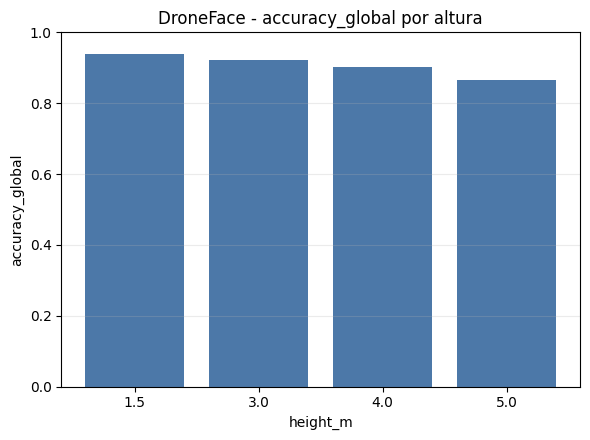

In [10]:
droneface_by_height = compute_grouped_metrics(results_df, ["height_m"])
by_height_path = TABLES_DIR / "droneface_by_height.csv"
droneface_by_height.to_csv(by_height_path, index=False)
display(droneface_by_height)

height_fig_path = FIGS_DIR / "metrics" / "droneface_accuracy_by_height.png"
plot_metric_bar(
    droneface_by_height,
    "height_m",
    "accuracy_global",
    "DroneFace - accuracy_global por altura",
    "accuracy_global",
    height_fig_path,
)
print(f"Tabla guardada en: {by_height_path}")
print(f"Figura generada: {height_fig_path}")


## 12. Experimento A: resultados por distancia


,dataset,distance_m,total_probe,detected_count,detection_rate,correct_count,accuracy_conditional,accuracy_global,mean_similarity_correct,mean_similarity_incorrect
0,DroneFace,2.0,28,28,1.000000,28,1.000000,1.000000,0.482237,NaN
1,DroneFace,2.5,28,28,1.000000,28,1.000000,1.000000,0.504483,NaN
2,DroneFace,3.0,28,28,1.000000,28,1.000000,1.000000,0.506857,NaN
3,DroneFace,3.5,28,28,1.000000,28,1.000000,1.000000,0.508608,NaN
4,DroneFace,4.0,28,28,1.000000,28,1.000000,1.000000,0.497150,NaN
5,DroneFace,4.5,28,28,1.000000,28,1.000000,1.000000,0.496226,NaN
6,DroneFace,5.0,28,28,1.000000,28,1.000000,1.000000,0.472587,NaN
7,DroneFace,5.5,28,28,1.000000,28,1.000000,1.000000,0.462116,NaN
8,DroneFace,6.0,28,28,1.000000,28,1.000000,1.000000,0.453275,NaN
9,DroneFace,6.5,28,28,1.000000,28,1.000000,1.000000,0.434521,NaN


Saved figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_accuracy_by_distance.png
Tabla guardada en: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\tables\droneface_by_distance.csv
Figura generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_accuracy_by_distance.png


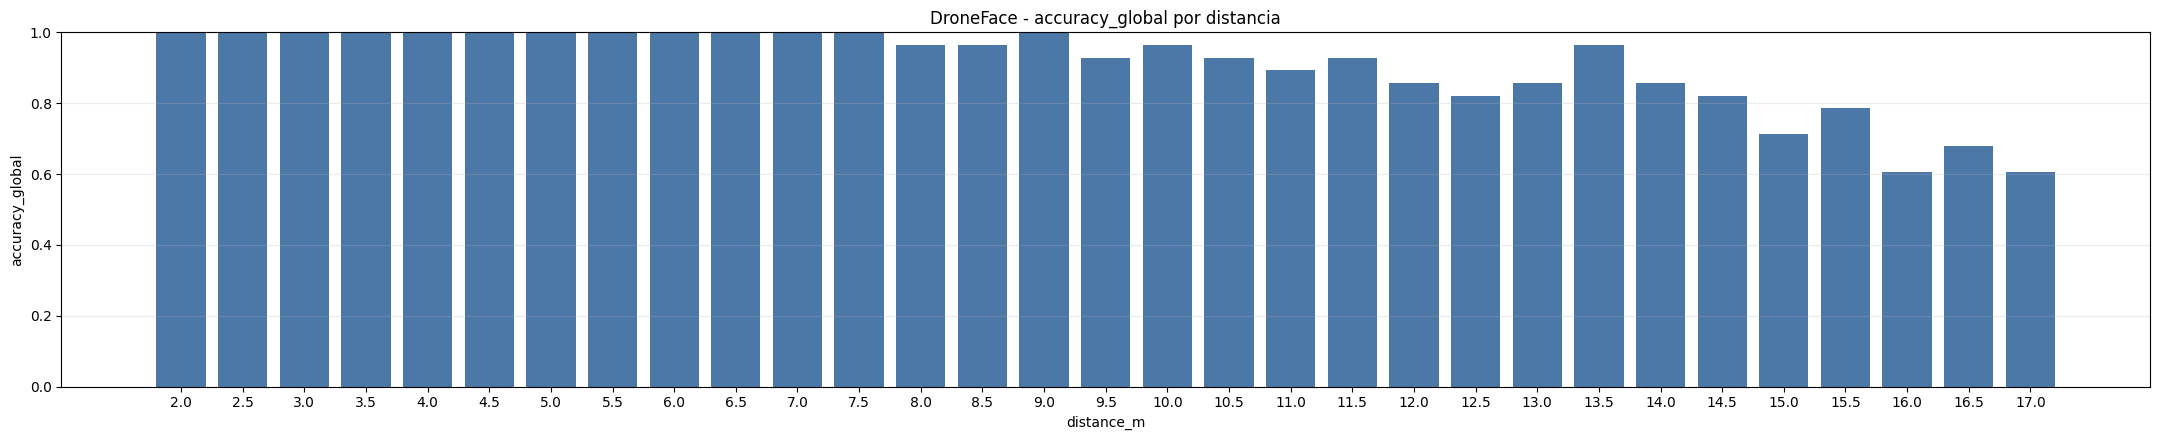

In [11]:
droneface_by_distance = compute_grouped_metrics(results_df, ["distance_m"])
by_distance_path = TABLES_DIR / "droneface_by_distance.csv"
droneface_by_distance.to_csv(by_distance_path, index=False)
display(droneface_by_distance)

distance_fig_path = FIGS_DIR / "metrics" / "droneface_accuracy_by_distance.png"
plot_metric_bar(
    droneface_by_distance,
    "distance_m",
    "accuracy_global",
    "DroneFace - accuracy_global por distancia",
    "accuracy_global",
    distance_fig_path,
)
print(f"Tabla guardada en: {by_distance_path}")
print(f"Figura generada: {distance_fig_path}")


## 13. Experimento A: resultados por altura y distancia


,dataset,height_m,distance_m,total_probe,detected_count,detection_rate,correct_count,accuracy_conditional,accuracy_global,mean_similarity_correct,mean_similarity_incorrect
0,DroneFace,1.5,2.0,7,7,1.000000,7,1.000000,1.000000,0.647311,NaN
1,DroneFace,1.5,2.5,7,7,1.000000,7,1.000000,1.000000,0.631491,NaN
2,DroneFace,1.5,3.0,7,7,1.000000,7,1.000000,1.000000,0.623093,NaN
3,DroneFace,1.5,3.5,7,7,1.000000,7,1.000000,1.000000,0.587637,NaN
4,DroneFace,1.5,4.0,7,7,1.000000,7,1.000000,1.000000,0.558980,NaN
5,DroneFace,1.5,4.5,7,7,1.000000,7,1.000000,1.000000,0.531550,NaN
6,DroneFace,1.5,5.0,7,7,1.000000,7,1.000000,1.000000,0.504415,NaN
7,DroneFace,1.5,5.5,7,7,1.000000,7,1.000000,1.000000,0.482926,NaN
8,DroneFace,1.5,6.0,7,7,1.000000,7,1.000000,1.000000,0.465462,NaN
9,DroneFace,1.5,6.5,7,7,1.000000,7,1.000000,1.000000,0.435011,NaN


Saved figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_accuracy_height_distance.png
Saved figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_detection_vs_accuracy.png
Tabla guardada en: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\tables\droneface_by_height_distance.csv
Figura heatmap generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_accuracy_height_distance.png
Figura resumen generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_detection_vs_accuracy.png


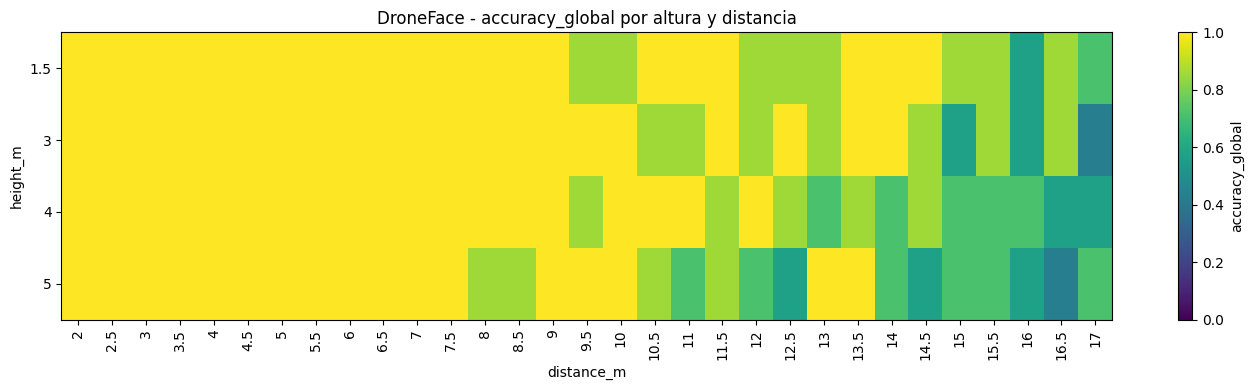

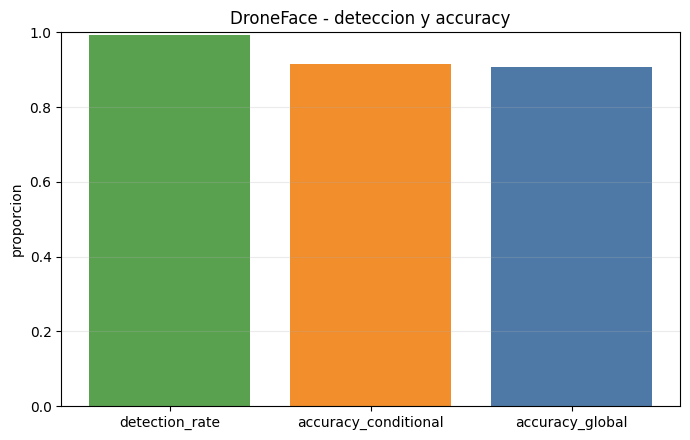

In [12]:
droneface_by_height_distance = compute_grouped_metrics(results_df, ["height_m", "distance_m"])
by_height_distance_path = TABLES_DIR / "droneface_by_height_distance.csv"
droneface_by_height_distance.to_csv(by_height_distance_path, index=False)
display(droneface_by_height_distance.head(20))

heatmap_path = FIGS_DIR / "metrics" / "droneface_accuracy_height_distance.png"
plot_accuracy_heatmap_height_distance(droneface_by_height_distance, heatmap_path)

summary_fig_path = FIGS_DIR / "metrics" / "droneface_detection_vs_accuracy.png"
plot_detection_vs_accuracy(summary_global_df, summary_fig_path)

print(f"Tabla guardada en: {by_height_distance_path}")
print(f"Figura heatmap generada: {heatmap_path}")
print(f"Figura resumen generada: {summary_fig_path}")


## 14. Visualizacion de casos correctos y fallidos


Saved figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\recognition\droneface_correct_incorrect.png
Figura generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\recognition\droneface_correct_incorrect.png


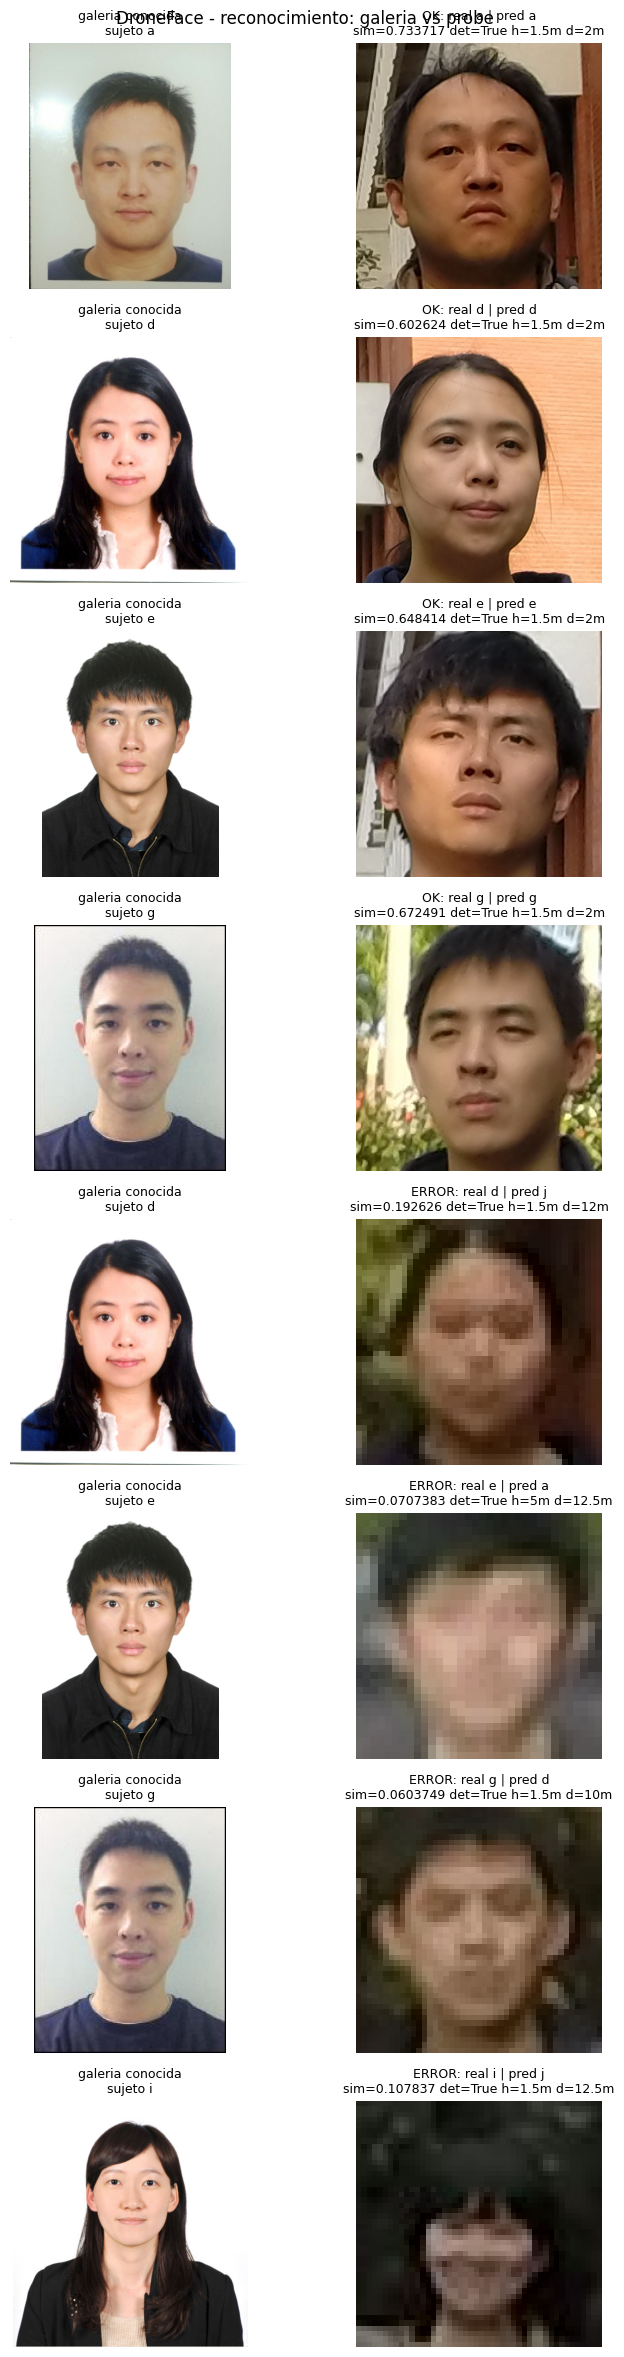

In [13]:
recognition_fig_path = FIGS_DIR / "recognition" / "droneface_correct_incorrect.png"
plot_recognition_examples(results_df, recognition_fig_path, max_correct=4, max_incorrect=4, index_df=drone_df)
print(f"Figura generada: {recognition_fig_path}")


## 15. Matriz de confusion


Saved figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_confusion_matrix.png
Figura generada: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_confusion_matrix.png


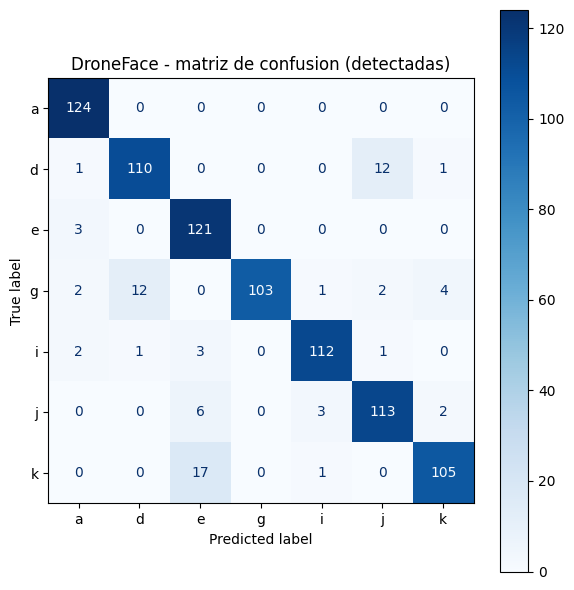

In [14]:
confusion_fig_path = FIGS_DIR / "metrics" / "droneface_confusion_matrix.png"
plot_confusion_matrix(results_df, confusion_fig_path)
print(f"Figura generada: {confusion_fig_path}")


## 16. Experimento B: reconocimiento sobre imagenes completas del dron

Este experimento usa `photos_all`, que contiene imagenes originales completas del dron (`image_type == "eo"`). A diferencia del Experimento A, aqui el modelo primero debe detectar rostros dentro de la imagen completa.

Para que el pipeline sea auditable, se guardan imagenes completas con bounding boxes y recortes (`crops`) de cada rostro detectado. La metrica principal de reconocimiento usa el embedding que InsightFace ya calcula para cada deteccion en la imagen completa.

Esto evita medir dos veces la deteccion. Si se vuelve a correr el detector sobre el crop rectangular guardado, muchos crops fallan aunque la cara ya habia sido detectada en la imagen original; eso corresponde a otro diagnostico, no a la metrica principal de B.

El Experimento B queda configurado con `det_size=(1280, 1280)`, porque el barrido corregido muestra que es la configuracion con mejor recuperacion de identidades esperadas en imagen completa.

Las etiquetas de `photos_all` son compuestas (`ab`, `cd`, `ef`, `gh`, `ijk`). Por eso la evaluacion se reporta como recuperacion de identidades esperadas por imagen. Los sujetos sin galeria (`b`, `c`, `f`, `h`) se reportan aparte y no se cuentan como error de reconocimiento.

Importante: `photos_all` no tiene identidad anotada por bounding box. Por lo tanto, este experimento no reporta TP, FP, FN, precision ni F1 por rostro. Las identidades predichas que no pertenecen al conjunto esperado se informan como identidades inesperadas, no como falsos positivos verificados.


In [ ]:
EXPERIMENT_B_DET_SIZE = (1280, 1280)
experiment_b_suffix = f"det{EXPERIMENT_B_DET_SIZE[0]}"

full_crops_path = RESULTS_DIR / "droneface_full_image_crops.csv"
full_crop_recognition_path = RESULTS_DIR / "droneface_full_image_crop_recognition.csv"
full_detections_path = RESULTS_DIR / "droneface_full_images_detections.csv"
full_results_path = RESULTS_DIR / "droneface_full_images_results.csv"
full_summary_path = TABLES_DIR / "droneface_full_images_summary.csv"
full_by_height_path = TABLES_DIR / "droneface_full_images_by_height.csv"
full_by_distance_path = TABLES_DIR / "droneface_full_images_by_distance.csv"
full_by_height_distance_path = TABLES_DIR / "droneface_full_images_by_height_distance.csv"
comparison_path = TABLES_DIR / "droneface_experiment_a_vs_b.csv"

full_crops_dir = CROPS_DIR / f"full_images_{experiment_b_suffix}"
full_review_dir = FIGS_DIR / "detection" / f"full_images_review_{experiment_b_suffix}"
full_detection_fig = FIGS_DIR / "detection" / "droneface_full_image_detections.png"
comparison_fig = FIGS_DIR / "metrics" / "droneface_experiment_a_vs_b.png"
full_recall_distance_fig = FIGS_DIR / "metrics" / "droneface_full_image_recall_by_distance.png"
full_recall_heatmap_fig = FIGS_DIR / "metrics" / "droneface_full_image_recall_height_distance.png"

if "model_b" not in globals() or getattr(model_b, "det_size", None) != EXPERIMENT_B_DET_SIZE:
    model_b = FaceRecognizerArcFace(model_name="buffalo_l", det_size=EXPERIMENT_B_DET_SIZE, allow_cuda=False)

print(f"Experimento B det_size: {model_b.det_size}")

drone_df = pd.read_csv(INDEX_DIR / "droneface_index.csv")
gallery_embeddings = load_gallery_npz(EMBEDDINGS_DIR / "droneface_gallery_embeddings.npz")

# 1) Guardar crops y figuras de revision para auditoria visual.
full_crops_df = detect_and_save_full_image_crops(
    drone_df,
    model_b,
    crops_dir=full_crops_dir,
    review_dir=full_review_dir,
    crops_path=full_crops_path,
    gallery_subjects=gallery_embeddings.keys(),
    padding=0.20,
)

# 2) Evaluacion principal: deteccion + embedding de InsightFace en la imagen completa.
full_detections_df, full_results_df = evaluate_full_images(
    drone_df,
    gallery_embeddings,
    model_b,
    detections_path=full_detections_path,
    results_path=full_results_path,
)

# 3) Tabla por crop vinculada a la prediccion de la deteccion original.
full_crop_recognition_df = build_crop_recognition_from_full_image_detections(
    full_crops_df,
    full_detections_df,
    recognition_path=full_crop_recognition_path,
)

full_summary_df = compute_full_image_summary(full_results_df)
full_by_height_df = compute_full_image_grouped_metrics(full_results_df, ["height_m"])
full_by_distance_df = compute_full_image_grouped_metrics(full_results_df, ["distance_m"])
full_by_height_distance_df = compute_full_image_grouped_metrics(full_results_df, ["height_m", "distance_m"])

full_summary_df.to_csv(full_summary_path, index=False)
full_by_height_df.to_csv(full_by_height_path, index=False)
full_by_distance_df.to_csv(full_by_distance_path, index=False)
full_by_height_distance_df.to_csv(full_by_height_distance_path, index=False)

summary_a_df = pd.read_csv(TABLES_DIR / "summary_global.csv")
comparison_df = build_experiment_a_b_comparison(summary_a_df, full_summary_df)
comparison_df.to_csv(comparison_path, index=False)

display(full_summary_df)
display(comparison_df)

plot_full_image_detections(full_results_df, full_detections_df, full_detection_fig, max_images=6)
plot_experiment_a_vs_b(comparison_df, comparison_fig)
plot_full_image_recall_by_distance(full_by_distance_df, full_recall_distance_fig)
plot_full_image_recall_heatmap_height_distance(full_by_height_distance_df, full_recall_heatmap_fig)

print(f"Crops guardados en: {full_crops_dir}")
print(f"Imagenes con cajas guardadas en: {full_review_dir}")
print(f"Metadata de crops: {full_crops_path}")
print(f"Reconocimiento por crop desde deteccion original: {full_crop_recognition_path}")
print(f"Resultados B agregados: {full_results_path}")
print(f"Resumen B: {full_summary_path}")
print(f"Comparacion A vs B: {comparison_path}")
print(f"Figura detecciones B: {full_detection_fig}")
print(f"Figura A vs B: {comparison_fig}")
print(f"Figura recall por distancia B (promedio sobre alturas): {full_recall_distance_fig}")
print(f"Figura heatmap B altura-distancia: {full_recall_heatmap_fig}")


## 17. Experimento C: degradacion sintetica controlada

Este experimento mide el reconocimiento de identidad en un escenario donde la verdad terreno si esta definida por imagen. Se toman probes de `photos_all_faces` con identidad conocida, preferentemente aquellos que el Experimento A ya reconoce correctamente, y se generan versiones degradadas en memoria.

Las degradaciones simulan ruido visual compatible con captura desde dron: baja resolucion con reescalado, Gaussian blur, compresion JPEG y traslacion leve. No se aplica rotacion en esta version.

La metrica principal es `rank1_accuracy_global`: proporcion de probes sinteticos cuyo vecino mas cercano en la galeria coincide con la identidad real.


In [ ]:
synthetic_results_path = RESULTS_DIR / "droneface_synthetic_degradation_results.csv"
synthetic_summary_path = TABLES_DIR / "droneface_synthetic_degradation_summary.csv"
synthetic_rank1_fig = FIGS_DIR / "metrics" / "droneface_synthetic_degradation_rank1.png"
synthetic_examples_fig = FIGS_DIR / "recognition" / "droneface_synthetic_degradation_examples.png"
SYNTHETIC_MAX_PROBES_PER_SUBJECT = 30

if "model_c" not in globals() or getattr(model_c, "det_size", None) != (320, 320):
    model_c = FaceRecognizerArcFace(model_name="buffalo_l", det_size=(320, 320), allow_cuda=False)

drone_df = pd.read_csv(INDEX_DIR / "droneface_index.csv")
a_results_df = pd.read_csv(RESULTS_DIR / "droneface_results.csv")
gallery_embeddings = load_gallery_npz(EMBEDDINGS_DIR / "droneface_gallery_embeddings.npz")

synthetic_results_df, synthetic_summary_df = run_synthetic_degradation_experiment(
    drone_df,
    a_results_df,
    gallery_embeddings,
    model_c,
    degradation_levels=DEFAULT_DEGRADATIONS,
    max_probes_per_subject=SYNTHETIC_MAX_PROBES_PER_SUBJECT,
    results_path=synthetic_results_path,
    summary_path=synthetic_summary_path,
)

display(synthetic_summary_df)
plot_synthetic_degradation_summary(synthetic_summary_df, synthetic_rank1_fig)
plot_synthetic_degradation_examples(
    drone_df,
    degradation_levels=DEFAULT_DEGRADATIONS,
    out_path=synthetic_examples_fig,
    subject_ids=gallery_embeddings.keys(),
)

print(f"Resultados Exp C: {synthetic_results_path}")
print(f"Resumen Exp C: {synthetic_summary_path}")
print(f"Figura Rank-1 Exp C: {synthetic_rank1_fig}")
print(f"Figura ejemplos Exp C: {synthetic_examples_fig}")


## 18. Experimento B: sensibilidad a det_size en imagen completa

Se probo el Experimento B con `det_size` 320, 640, 1024 y 1280. Esta prueba usa la metrica corregida: reconocimiento con los embeddings de la deteccion original. En este flujo, aumentar `det_size` mejora tanto la deteccion como la recuperacion de identidades esperadas en `photos_all`.

El resumen se lee desde `outputs/tables/droneface_full_images_det_size_summary.csv`, generado previamente porque ejecutar el barrido completo puede tardar bastante en CPU.


In [17]:
b_det_size_summary_path = TABLES_DIR / "droneface_full_images_det_size_summary.csv"
b_det_size_fig = FIGS_DIR / "metrics" / "droneface_full_image_det_size_sweep.png"

if b_det_size_summary_path.exists():
    b_det_size_summary_df = pd.read_csv(b_det_size_summary_path)
    display_cols = [
        "det_size",
        "recognition_mode",
        "images_with_detections",
        "image_detection_rate",
        "expected_identity_recall_global",
        "any_expected_found_rate",
        "all_expected_found_rate",
    ]
    display_cols = [col for col in display_cols if col in b_det_size_summary_df.columns]
    display(b_det_size_summary_df[display_cols])
    print(f"Figura resumen: {b_det_size_fig}")
else:
    print("No existe el resumen del barrido B por det_size. Ejecutar el barrido completo es opcional y puede tardar varios minutos.")


,det_size,recognition_mode,images_with_detections,image_detection_rate,expected_identity_recall_global,any_expected_found_rate,all_expected_found_rate
0,320,source_detection_embedding,56,0.090323,0.066820,0.074194,0.062903
1,640,source_detection_embedding,255,0.411290,0.332949,0.367742,0.325806
2,1024,source_detection_embedding,467,0.753226,0.638249,0.679032,0.622581
3,1280,source_detection_embedding,567,0.914516,0.788018,0.841935,0.775806


Figura resumen: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_full_image_det_size_sweep.png


## 19. Experimento adicional: sensibilidad del detector facial

Esta seccion prueba si el cuello de botella observado viene de la deteccion facial. Se repite el protocolo del Experimento A usando `det_size` 320, 640 y 1024 en InsightFace/ArcFace.

El baseline principal queda configurado con `det_size=(320, 320)`, porque en el barrido fue la configuracion con mejor `accuracy_global` y mejor `detection_rate`. Los otros resultados se conservan para mostrar que este parametro fue ajustado experimentalmente.

Un resultado `no detection` significa que el detector no genero una caja facial valida para continuar con el embedding. No significa que visualmente no exista una cara en la imagen.

Las figuras ya mostradas en celdas anteriores solo cambian si se vuelve a ejecutar el notebook.



=== det_size=320 ===
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\w600k_r50.onnx recognition ['No

Building gallery:   0%|          | 0/7 [00:00<?, ?it/s]

C:\Users\shipa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Saved gallery embeddings: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\embeddings\droneface_gallery_embeddings_det320.npz
Saved gallery failures: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\tables\gallery_failures_droneface_det320.csv


Evaluating probes:   0%|          | 0/868 [00:00<?, ?it/s]

C:\Users\shipa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


... (13 outputs left out)

,det_size,dataset,n_gallery_subjects,total_probe,detected_count,detection_rate,correct_count,accuracy_conditional,accuracy_global,mean_similarity_correct,mean_similarity_incorrect,gallery_subjects_before_detection,gallery_subjects_with_embedding,probes_excluded_no_gallery,probes_evaluated,runtime_seconds
0,320,DroneFace,7,868,862,0.993088,788,0.914153,0.907834,0.342960,0.132640,7,7,496,868,255.736482
1,640,DroneFace,7,868,486,0.559908,424,0.872428,0.488479,0.288342,0.129895,7,7,496,868,212.214941
2,1024,DroneFace,3,372,1,0.002688,0,0.000000,0.000000,NaN,-0.020966,7,3,992,372,93.850978


Saved det_size summary figure: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_det_size_detection_accuracy.png
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\shipa/.insightface\models\buffalo_l\genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CP

C:\Users\shipa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Saved det_size detection examples: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\detection\droneface_det_size_examples.png
Resultados individuales: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\results\droneface_det_size_results.csv
Resumen por det_size: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs\tables\droneface_det_size_summary.csv
Figura metricas: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\metrics\droneface_det_size_detection_accuracy.png
Figura ejemplos deteccion: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\figs\detection\droneface_det_size_examples.png


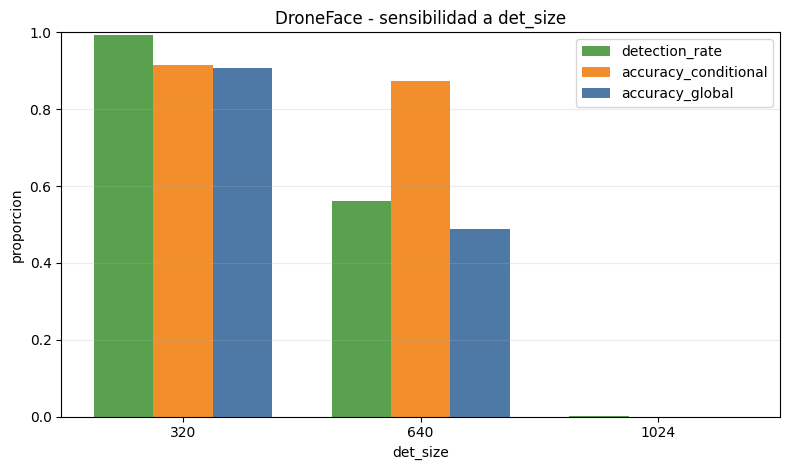

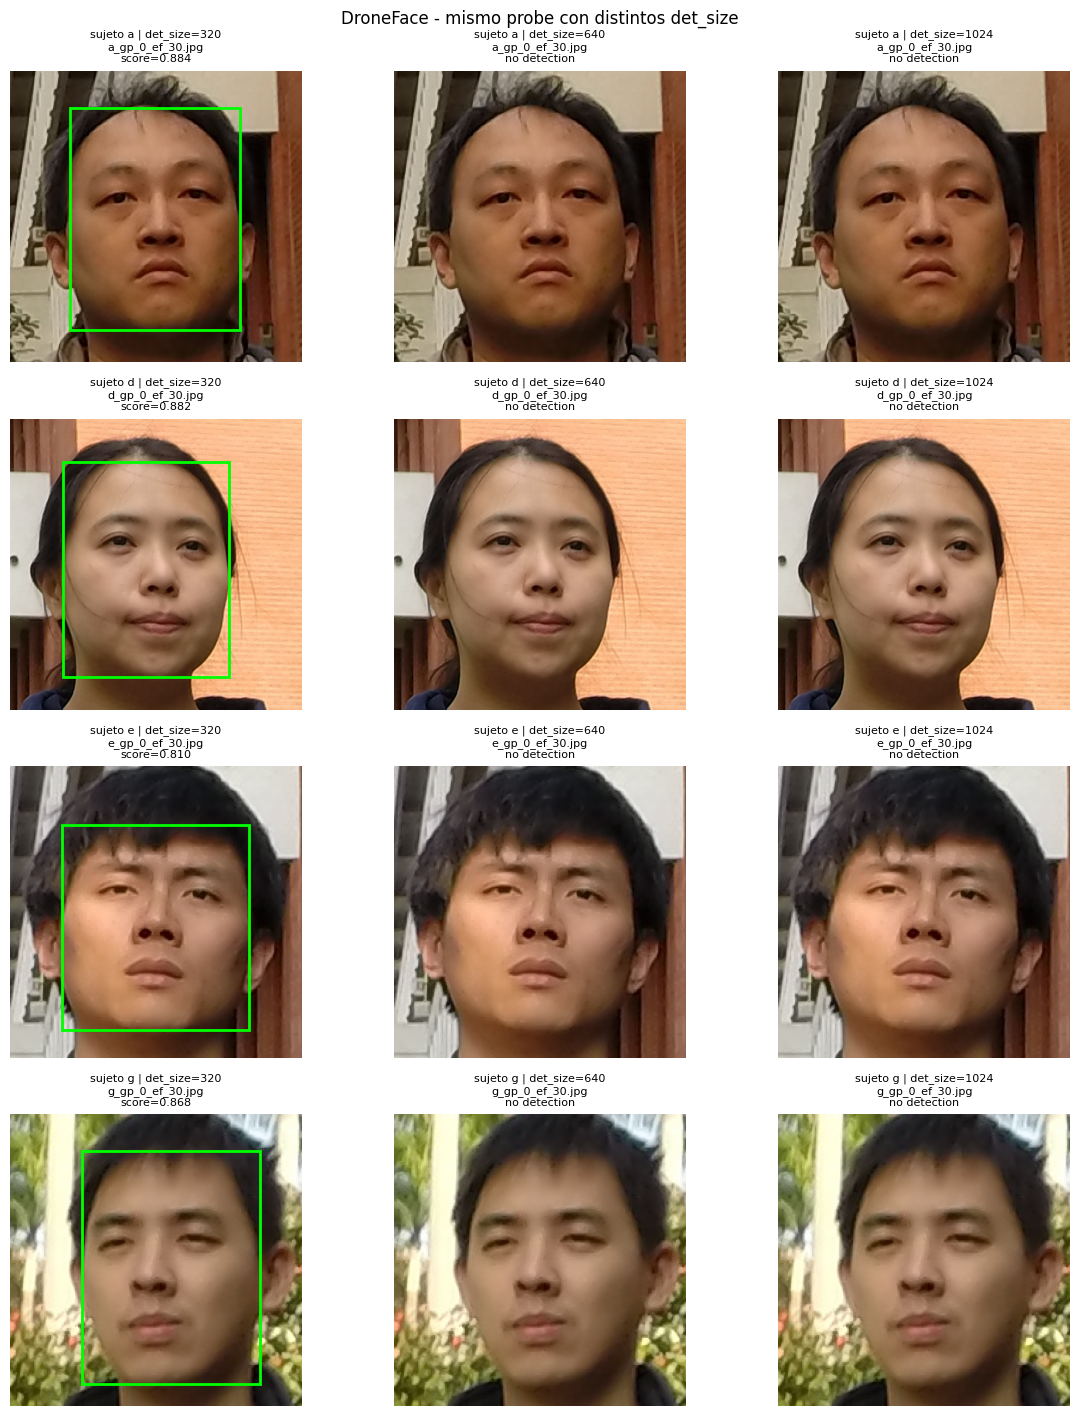

In [18]:
from src.detection_experiments import (
    run_det_size_sweep,
    plot_det_size_summary,
    plot_det_size_detection_examples,
)

DET_SIZES = (320, 640, 1024)

det_size_results_path = RESULTS_DIR / "droneface_det_size_results.csv"
det_size_summary_path = TABLES_DIR / "droneface_det_size_summary.csv"
det_size_metric_fig = FIGS_DIR / "metrics" / "droneface_det_size_detection_accuracy.png"
det_size_examples_fig = FIGS_DIR / "detection" / "droneface_det_size_examples.png"

if not (INDEX_DIR / "droneface_index.csv").exists():
    raise FileNotFoundError("Falta outputs/indexes/droneface_index.csv. Ejecuta primero la construccion del indice.")

drone_df = pd.read_csv(INDEX_DIR / "droneface_index.csv")

# Este barrido puede tardar varios minutos en CPU porque inicializa/evalua el modelo tres veces.
det_size_results_df, det_size_summary_df = run_det_size_sweep(
    drone_df,
    det_sizes=DET_SIZES,
    model_name="buffalo_l",
    allow_cuda=False,
    results_path=det_size_results_path,
    summary_path=det_size_summary_path,
)

display(det_size_summary_df)

plot_det_size_summary(det_size_summary_df, det_size_metric_fig)
plot_det_size_detection_examples(
    drone_df,
    det_sizes=DET_SIZES,
    model_name="buffalo_l",
    allow_cuda=False,
    out_path=det_size_examples_fig,
)

print(f"Resultados individuales: {det_size_results_path}")
print(f"Resumen por det_size: {det_size_summary_path}")
print(f"Figura metricas: {det_size_metric_fig}")
print(f"Figura ejemplos deteccion: {det_size_examples_fig}")


## 20. Discusion preliminar automatica basada unicamente en resultados calculados


In [ ]:
discussion = generate_preliminary_discussion(
    summary_global_df,
    droneface_by_height,
    droneface_by_distance,
    droneface_by_height_distance,
)

if 'full_summary_df' in globals() and not full_summary_df.empty:
    a_row = summary_global_df.iloc[0]
    b_row = full_summary_df.iloc[0]
    discussion += "\n\nEn el Experimento B sobre imagenes completas, se guardaron imagenes con bounding boxes y crops de los rostros detectados para auditoria visual. "
    discussion += "La metrica principal usa los embeddings que InsightFace calcula en la deteccion original de la imagen completa, evitando una segunda deteccion artificial dentro del crop. "
    discussion += "La recuperacion global de identidades esperadas fue "
    discussion += f"{b_row['expected_identity_recall_global']:.2%}, con tasa de imagenes con deteccion de {b_row['image_detection_rate']:.2%}. "
    discussion += f"En comparacion, el Experimento A sobre rostros recortados obtuvo accuracy_global de {a_row['accuracy_global']:.2%}. "
    if b_row['expected_identity_recall_global'] < a_row['accuracy_global']:
        discussion += "La caida entre A y B sugiere que pasar desde imagen completa del dron a rostro detectable y reconocible es mas dificil que evaluar rostros ya recortados. "
    discussion += "Esta metrica de B no es accuracy por rostro anotado, porque photos_all no incluye bounding boxes con identidad. "
    discussion += "Por la misma razon, B no reporta TP, FP, FN, precision ni F1 por rostro; solo recuperacion de identidades esperadas a nivel de imagen. "
    if 'unexpected_predicted_identities' in full_summary_df.columns:
        discussion += "Las identidades predichas fuera del conjunto esperado se informan como identidades inesperadas: "
        discussion += f"{int(b_row['unexpected_predicted_identities'])} apariciones a nivel de conjunto por imagen. "
    if 'exact_expected_set_match_rate' in full_summary_df.columns and 'mean_jaccard_set_similarity' in full_summary_df.columns:
        discussion += f"El exact_expected_set_match_rate fue {b_row['exact_expected_set_match_rate']:.2%} y el mean_jaccard_set_similarity fue {b_row['mean_jaccard_set_similarity']:.2%}."

if 'synthetic_summary_df' in globals() and not synthetic_summary_df.empty:
    clean_row = synthetic_summary_df[synthetic_summary_df['degradation_level'] == 'clean_reference']
    strong_row = synthetic_summary_df[synthetic_summary_df['degradation_level'] == 'strong']
    discussion += "\n\nEl Experimento C evalua el modulo de reconocimiento en un escenario controlado con identidad conocida. "
    discussion += "A diferencia de B, aqui cada probe degradado tiene etiqueta real, por lo que rank1_accuracy_global si mide acierto de reconocimiento por imagen. "
    if not clean_row.empty:
        discussion += f"Con la referencia limpia, rank1_accuracy_global fue {clean_row.iloc[0]['rank1_accuracy_global']:.2%}. "
    if not strong_row.empty:
        discussion += f"Con degradacion fuerte, rank1_accuracy_global fue {strong_row.iloc[0]['rank1_accuracy_global']:.2%}. "
    discussion += "Este resultado sirve para analizar robustez a blur, baja resolucion, compresion y pequenas traslaciones sin depender de anotaciones manuales por bounding box."

b_det_size_summary_path = TABLES_DIR / "droneface_full_images_det_size_summary.csv"
if b_det_size_summary_path.exists():
    b_det_size_summary_df = pd.read_csv(b_det_size_summary_path)
    if not b_det_size_summary_df.empty:
        best_recall_row = b_det_size_summary_df.sort_values("expected_identity_recall_global", ascending=False).iloc[0]
        best_detection_row = b_det_size_summary_df.sort_values("image_detection_rate", ascending=False).iloc[0]
        discussion += "\n\nEn el barrido corregido del Experimento B, el mejor valor por recuperacion de identidades esperadas fue "
        discussion += f"det_size={int(best_recall_row['det_size'])}, con {best_recall_row['expected_identity_recall_global']:.2%}. "
        discussion += "El mayor porcentaje de imagenes con alguna deteccion fue "
        discussion += f"det_size={int(best_detection_row['det_size'])}, con {best_detection_row['image_detection_rate']:.2%}. "
        discussion += "En este flujo corregido, aumentar det_size mejoro el pipeline de imagen completa."

discussion_path = TABLES_DIR / "preliminary_discussion.txt"
discussion_path.write_text(discussion, encoding="utf-8")
print(f"Discusion guardada en: {discussion_path}")
display(Markdown(discussion))


## 21. Limitaciones y trabajo futuro

Limitaciones:

- Solo se usa DroneFace porque SCface no esta disponible.
- El modelo es preentrenado y no fue ajustado al dataset.
- El experimento A es closed-set, por lo que no evalua sujetos desconocidos.
- El experimento A usa `photos_all_faces`, que son rostros ya recortados y representa un baseline simplificado.
- El experimento B usa `photos_all`, pero se reporta como recuperacion de identidades esperadas por imagen porque no hay bounding boxes con identidad. Por eso B no reporta TP, FP, FN, precision ni F1 por rostro.
- El experimento C usa degradacion sintetica; ayuda a medir robustez del reconocimiento, pero no reemplaza una anotacion manual real de los crops de B.
- El rendimiento depende de la deteccion facial previa.
- `trio_cam` y `trio_gp` no se usan aun en la evaluacion principal porque contienen multiples personas y requieren un protocolo especifico.
- No se implementa control de dron.
- No se evalua tiempo real.
- El uso de modelos preentrenados debe mantenerse en contexto academico/no comercial y respetar licencias.

Trabajo futuro:

- Mejorar la deteccion y asociacion de rostros en `photos_all`.
- Etiquetar manualmente los crops/bounding boxes del Experimento B para medir TP, FP, FN, precision, recall y F1 reales por rostro detectado.
- Evaluar imagenes con multiples personas de `trio_cam` y `trio_gp`.
- Probar open-set recognition con umbral de desconocido.
- Comparar ArcFace con otro metodo.
- Analizar sensibilidad a resolucion, blur, altura y distancia.
- Estudiar factibilidad de procesamiento en tiempo real.
- Eventualmente conectar con un sistema de captura o seguimiento, pero no en este avance.
